# Studi Kasus HCI & Visualisasi Data: Dashboard Penjualan untuk Budi

## Skenario
Budi adalah analis data yang harus menyiapkan laporan penjualan sebelum rapat. Dashboard lamanya **lambat** dan **menampilkan terlalu banyak angka tanpa pengelompokan**. Notebook ini mengimplementasikan konsep dari materi menjadi kode:

| Bagian | Konsep dari materi |
|---|---|
| 1 | Persona, skenario, functional & non-functional requirements |
| 2 | Dataset & pengecekan non-functional requirement |
| 3 | Pemilihan grafik sesuai tujuan (line, bar, scatter, pie) |
| 4 | Visualisasi jujur vs menyesatkan (etika) |
| 5 | Warna, kontras, aksesibilitas, dan prinsip Gestalt |
| 6 | Dashboard interaktif: *overview → zoom and filter → details on demand* |
| 7 | Heuristik Nielsen dalam kode (feedback, pencegahan error, konfirmasi) |
| 8 | Evaluasi kegunaan dengan skor SUS |

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.0f}".format
np.random.seed(42)
print("Library siap dipakai.")

Library siap dipakai.


## 1. Persona, Skenario, dan Kebutuhan Sistem
Persona adalah profil fiktif berdasarkan riset pengguna. Prinsip utama: ***You are not your user***, jadi desain harus berangkat dari kebutuhan Budi, bukan asumsi perancang.

In [2]:
persona = {
    "Nama": "Budi",
    "Peran": "Analis data",
    "Tujuan": "Menyiapkan ringkasan penjualan yang cepat dipahami sebelum rapat",
    "Kebiasaan teknologi": "Memakai tablet saat rapat, terbiasa dengan Excel",
    "Masalah": "Dashboard lambat; terlalu banyak angka tanpa pengelompokan",
}
skenario = [
    "1. Budi membuka dashboard melalui tablet.",
    "2. Budi menyaring data penjualan di Jakarta.",
    "3. Budi membagikan grafik saat rapat.",
]
display(pd.Series(persona, name="Persona").to_frame())
print("\n".join(skenario))

,Persona
Nama,Budi
Peran,Analis data
Tujuan,Menyiapkan ringkasan penjualan yang cepat dipa...
Kebiasaan teknologi,"Memakai tablet saat rapat, terbiasa dengan Excel"
Masalah,Dashboard lambat; terlalu banyak angka tanpa p...


1. Budi membuka dashboard melalui tablet.
2. Budi menyaring data penjualan di Jakarta.
3. Budi membagikan grafik saat rapat.


In [3]:
functional = pd.DataFrame({
    "ID": ["F1", "F2", "F3", "F4"],
    "Functional requirement": [
        "Menyaring data berdasarkan tanggal",
        "Menyaring data berdasarkan kota dan kategori",
        "Menampilkan detail transaksi saat diminta",
        "Mengekspor grafik sebagai gambar",
    ],
    "Diimplementasikan di": ["Bagian 6", "Bagian 6", "Bagian 6", "Bagian 6 (tombol ekspor)"],
})
non_functional = pd.DataFrame({
    "ID": ["N1", "N2"],
    "Non-functional requirement": [
        "Data termuat dalam < 2 detik",
        "Kontras teks terhadap latar minimal 4.5:1 (WCAG AA)",
    ],
    "Cara verifikasi": ["Ukur waktu (Bagian 2)", "Hitung rasio kontras (Bagian 5)"],
})
display(functional); display(non_functional)

,ID,Functional requirement,Diimplementasikan di
0,F1,Menyaring data berdasarkan tanggal,Bagian 6
1,F2,Menyaring data berdasarkan kota dan kategori,Bagian 6
2,F3,Menampilkan detail transaksi saat diminta,Bagian 6
3,F4,Mengekspor grafik sebagai gambar,Bagian 6 (tombol ekspor)


,ID,Non-functional requirement,Cara verifikasi
0,N1,Data termuat dalam < 2 detik,Ukur waktu (Bagian 2)
1,N2,Kontras teks terhadap latar minimal 4.5:1 (WCA...,Hitung rasio kontras (Bagian 5)


## 2. Dataset dan Verifikasi Non-Functional Requirement (N1)
Data penjualan dibuat secara sintetis (seed tetap) agar notebook bisa dijalankan siapa saja tanpa file eksternal.

In [4]:
def buat_dataset(n=4000, seed=42):
    rng = np.random.default_rng(seed)
    tanggal = pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D")
    kota = rng.choice(["Jakarta", "Bandung", "Surabaya", "Medan", "Makassar"], n, p=[.35, .2, .2, .15, .1])
    kategori = rng.choice(["Elektronik", "Fashion", "Makanan", "Rumah Tangga"], n, p=[.3, .3, .25, .15])
    jumlah = rng.integers(1, 6, n)
    harga = pd.Series(kategori).map({"Elektronik": 2_500_000, "Fashion": 400_000,
                                     "Makanan": 120_000, "Rumah Tangga": 600_000}).values
    musim = 1 + 0.25*np.sin((tanggal.month.values - 3) / 12 * 2*np.pi)   # tren musiman
    penjualan = (harga * jumlah * musim * rng.normal(1, .12, n)).round(-3)
    biaya_iklan = (penjualan * rng.uniform(.03, .12, n)).round(-3)
    return pd.DataFrame({"tanggal": tanggal, "kota": kota, "kategori": kategori,
                         "jumlah": jumlah, "penjualan": penjualan, "biaya_iklan": biaya_iklan}
                        ).sort_values("tanggal").reset_index(drop=True)

mulai = time.perf_counter()
df = buat_dataset()
df["bulan"] = df["tanggal"].dt.to_period("M").dt.to_timestamp()
durasi = time.perf_counter() - mulai

print(f"Waktu muat data: {durasi:.3f} detik -> N1 {'TERPENUHI' if durasi < 2 else 'BELUM terpenuhi'}")
df.drop(columns="bulan").to_csv("data_penjualan.csv", index=False)
df.head()

Waktu muat data: 0.030 detik -> N1 TERPENUHI


,tanggal,kota,kategori,jumlah,penjualan,biaya_iklan,bulan
0,2025-01-01,Medan,Elektronik,3,"4,519,000","488,000",2025-01-01
1,2025-01-01,Makassar,Makanan,5,"542,000","18,000",2025-01-01
2,2025-01-01,Surabaya,Fashion,5,"1,669,000","65,000",2025-01-01
3,2025-01-01,Jakarta,Fashion,2,"611,000","37,000",2025-01-01
4,2025-01-01,Bandung,Fashion,3,"1,044,000","56,000",2025-01-01


## 3. Memilih Grafik Sesuai Tujuan Analisis
Setiap pertanyaan dijawab dengan jenis grafik yang sesuai: **line** untuk tren, **bar** untuk perbandingan kategori, **scatter** untuk hubungan dua variabel numerik, **pie** untuk proporsi (hanya jika kategori sedikit).

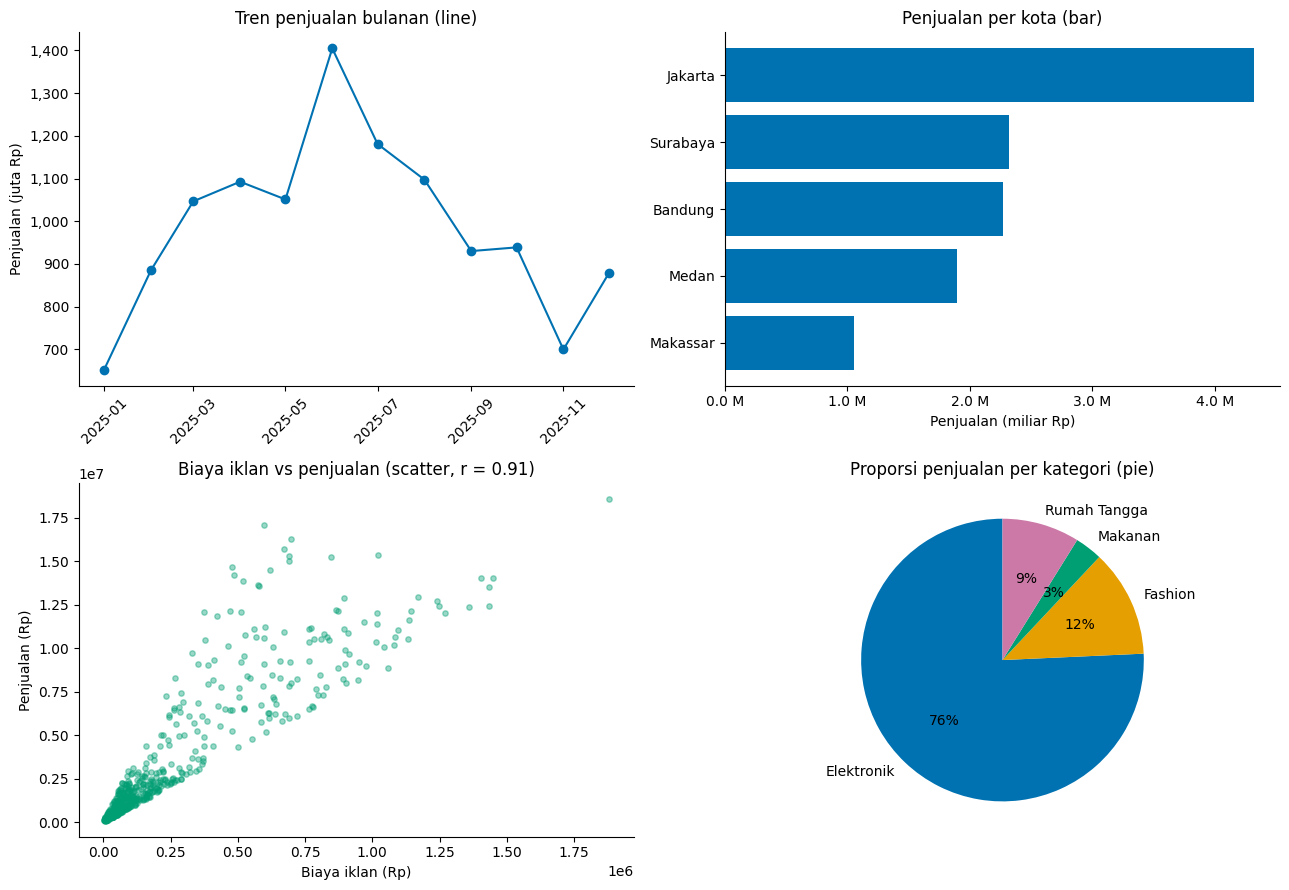

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
juta = lambda x, _: f"{x/1e6:,.0f} jt"
from matplotlib.ticker import FuncFormatter

# 1) Line chart: tren penjualan bulanan
tren = df.groupby("bulan")["penjualan"].sum()
ax[0,0].plot(tren.index, tren.values, marker="o", color="#0072B2")
ax[0,0].set_title("Tren penjualan bulanan (line)")
ax[0,0].set_ylabel("Penjualan (juta Rp)"); ax[0,0].yaxis.set_major_formatter(FuncFormatter(lambda x,_: f"{x/1e6:,.0f}"))
ax[0,0].tick_params(axis="x", rotation=45)

# 2) Bar chart: perbandingan antar kota (diurutkan agar mudah dibandingkan)
kota = df.groupby("kota")["penjualan"].sum().sort_values()
ax[0,1].barh(kota.index, kota.values, color="#0072B2")
ax[0,1].set_title("Penjualan per kota (bar)")
ax[0,1].xaxis.set_major_formatter(FuncFormatter(lambda x,_: f"{x/1e9:,.1f} M"))
ax[0,1].set_xlabel("Penjualan (miliar Rp)")

# 3) Scatter plot: hubungan biaya iklan vs penjualan
sampel = df.sample(600, random_state=1)
ax[1,0].scatter(sampel["biaya_iklan"], sampel["penjualan"], alpha=.4, s=15, color="#009E73")
r = df["biaya_iklan"].corr(df["penjualan"])
ax[1,0].set_title(f"Biaya iklan vs penjualan (scatter, r = {r:.2f})")
ax[1,0].set_xlabel("Biaya iklan (Rp)"); ax[1,0].set_ylabel("Penjualan (Rp)")

# 4) Pie chart: proporsi kategori (hanya 4 irisan -> masih terbaca)
kat = df.groupby("kategori")["penjualan"].sum()
ax[1,1].pie(kat, labels=kat.index, autopct="%1.0f%%", startangle=90,
            colors=["#0072B2", "#E69F00", "#009E73", "#CC79A7"])
ax[1,1].set_title("Proporsi penjualan per kategori (pie)")

plt.tight_layout(); plt.savefig("grafik_pemilihan_jenis.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Etika: Visualisasi Jujur vs Menyesatkan
Materi menegaskan visualisasi **tidak boleh** memakai skala atau tampilan yang menyesatkan. Contoh di bawah membandingkan dua kota dengan data yang sama.

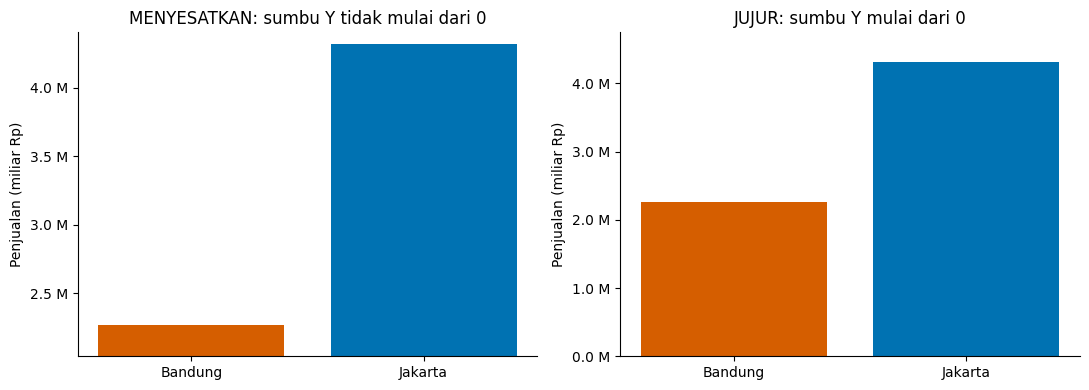

Rasio sebenarnya Jakarta : Bandung = 1.90 : 1
Pada grafik kiri, selisihnya tampak jauh lebih besar dari kenyataan.


In [6]:
dua_kota = df[df["kota"].isin(["Jakarta", "Bandung"])].groupby("kota")["penjualan"].sum()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(dua_kota.index, dua_kota.values, color=["#D55E00", "#0072B2"])
ax[0].set_ylim(dua_kota.min()*0.9, dua_kota.max()*1.02)       # sumbu dipotong
ax[0].set_title("MENYESATKAN: sumbu Y tidak mulai dari 0")
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda x,_: f"{x/1e9:.1f} M"))

ax[1].bar(dua_kota.index, dua_kota.values, color=["#D55E00", "#0072B2"])
ax[1].set_ylim(0, dua_kota.max()*1.1)
ax[1].set_title("JUJUR: sumbu Y mulai dari 0")
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda x,_: f"{x/1e9:.1f} M"))
for a in ax:
    a.set_ylabel("Penjualan (miliar Rp)")
plt.tight_layout(); plt.savefig("grafik_jujur_vs_menyesatkan.png", dpi=150, bbox_inches="tight"); plt.show()

rasio_nyata = dua_kota["Jakarta"] / dua_kota["Bandung"]
print(f"Rasio sebenarnya Jakarta : Bandung = {rasio_nyata:.2f} : 1")
print("Pada grafik kiri, selisihnya tampak jauh lebih besar dari kenyataan.")

## 5. Warna, Kontras, Aksesibilitas, dan Gestalt

**5a. Kontras (verifikasi N2).** Rumus kontras WCAG dihitung dari luminansi relatif dua warna.

In [7]:
def luminansi(hex_color):
    r, g, b = [int(hex_color.lstrip("#")[i:i+2], 16) / 255 for i in (0, 2, 4)]
    f = lambda c: c/12.92 if c <= 0.03928 else ((c + 0.055)/1.055) ** 2.4
    return 0.2126*f(r) + 0.7152*f(g) + 0.0722*f(b)

def rasio_kontras(fg, bg):
    l1, l2 = sorted([luminansi(fg), luminansi(bg)], reverse=True)
    return (l1 + 0.05) / (l2 + 0.05)

uji = [("#000000", "#FFFFFF"), ("#0072B2", "#FFFFFF"), ("#E69F00", "#FFFFFF"), ("#999999", "#FFFFFF"), ("#767676", "#FFFFFF")]
hasil = pd.DataFrame([{"Teks": a, "Latar": b, "Rasio": round(rasio_kontras(a, b), 2),
                       "Lulus AA (>=4.5)": "Ya" if rasio_kontras(a, b) >= 4.5 else "Tidak"} for a, b in uji])
hasil

,Teks,Latar,Rasio,Lulus AA (>=4.5)
0,#000000,#FFFFFF,21,Ya
1,#0072B2,#FFFFFF,5,Ya
2,#E69F00,#FFFFFF,2,Tidak
3,#999999,#FFFFFF,3,Tidak
4,#767676,#FFFFFF,5,Ya


**5b. Palet ramah buta warna & perhatian visual.** Warna dipakai untuk menarik perhatian pada satu hal penting (kota terbaik), sedangkan elemen lain dibuat netral. Palet Okabe-Ito tetap dapat dibedakan oleh pengguna buta warna, dan label langsung (bukan hanya warna) menjaga keterbacaan.

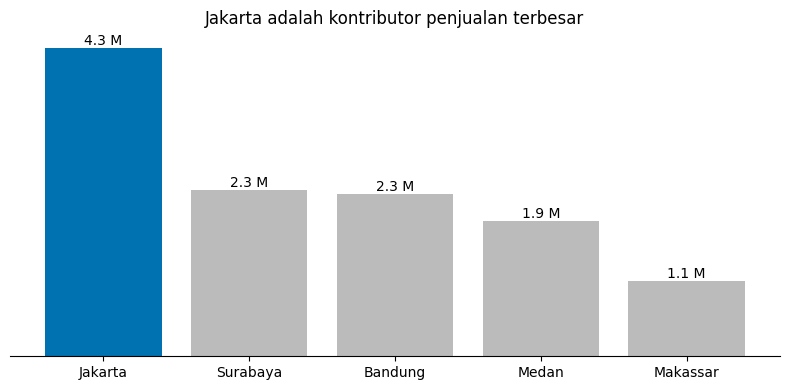

In [8]:
per_kota = df.groupby("kota")["penjualan"].sum().sort_values(ascending=False)
warna = ["#0072B2" if i == 0 else "#BBBBBB" for i in range(len(per_kota))]   # figure-ground: sorot satu

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(per_kota.index, per_kota.values, color=warna)
for b, v in zip(bars, per_kota.values):
    ax.text(b.get_x()+b.get_width()/2, v, f"{v/1e9:.1f} M", ha="center", va="bottom", fontsize=10)
ax.set_title(f"{per_kota.index[0]} adalah kontributor penjualan terbesar")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
plt.tight_layout(); plt.savefig("grafik_gestalt_sorot_kota.png", dpi=150, bbox_inches="tight"); plt.show()

Prinsip **Gestalt** yang diterapkan pada grafik di atas:
- **Similarity:** batang abu-abu dipersepsikan satu kelompok.
- **Figure–ground:** satu batang biru menonjol dari latar netral.
- **Proximity:** label angka diletakkan dekat batangnya.
- **Extraneous load rendah:** tanpa garis kisi, bayangan, atau efek 3D.

## 6. Dashboard Interaktif: Overview → Zoom and Filter → Details on Demand
Mengikuti skenario Budi: buka dashboard, **saring ke Jakarta**, lalu lihat **detail** dan **ekspor grafik**.

In [9]:
SEMUA = "Semua"
w_kota = widgets.Dropdown(options=[SEMUA] + sorted(df["kota"].unique()), value=SEMUA, description="Kota:")
w_kat  = widgets.Dropdown(options=[SEMUA] + sorted(df["kategori"].unique()), value=SEMUA, description="Kategori:")
w_tgl  = widgets.SelectionRangeSlider(
    options=[(t.strftime("%b %Y"), t) for t in sorted(df["bulan"].unique())],
    index=(0, df["bulan"].nunique()-1), description="Periode:", layout=widgets.Layout(width="520px"))
w_topn = widgets.IntSlider(value=5, min=3, max=15, description="Top N:")
w_ekspor = widgets.Button(description="Ekspor grafik (PNG)", button_style="info", icon="download")
w_out = widgets.Output()
status = widgets.HTML()

def saring(kota, kat, rentang):
    d = df[(df["bulan"] >= rentang[0]) & (df["bulan"] <= rentang[1])]
    if kota != SEMUA: d = d[d["kota"] == kota]
    if kat != SEMUA:  d = d[d["kategori"] == kat]
    return d

def gambar(_=None):
    status.value = "<i>Memuat…</i>"                    # heuristik: visibilitas status sistem
    with w_out:
        clear_output(wait=True)
        d = saring(w_kota.value, w_kat.value, w_tgl.value)
        if d.empty:                                      # heuristik: pesan kesalahan yang jelas
            print("Tidak ada data untuk kombinasi filter ini. Coba ubah kota, kategori, atau periode.")
            status.value = "<b style='color:#B00020'>Data kosong</b>"
            return
        # OVERVIEW: KPI ringkas
        k1, k2, k3 = d["penjualan"].sum(), len(d), d["penjualan"].mean()
        print(f"Total penjualan: Rp {k1:,.0f}   |   Transaksi: {k2:,}   |   Rata-rata/transaksi: Rp {k3:,.0f}")
        # ZOOM & FILTER: grafik tren dan komposisi
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
        t = d.groupby("bulan")["penjualan"].sum()
        ax[0].plot(t.index, t.values, marker="o", color="#0072B2")
        ax[0].set_title("Tren penjualan"); ax[0].tick_params(axis="x", rotation=45)
        ax[0].yaxis.set_major_formatter(FuncFormatter(lambda x,_: f"{x/1e6:,.0f} jt"))
        k = d.groupby("kategori")["penjualan"].sum().sort_values()
        ax[1].barh(k.index, k.values, color="#0072B2"); ax[1].set_title("Per kategori")
        ax[1].xaxis.set_major_formatter(FuncFormatter(lambda x,_: f"{x/1e6:,.0f} jt"))
        plt.tight_layout(); plt.show()
        globals()["_fig_terakhir"] = fig
        # DETAILS ON DEMAND: tabel transaksi terbesar
        print(f"\n{w_topn.value} transaksi terbesar pada filter ini:")
        display(d.nlargest(w_topn.value, "penjualan")[["tanggal", "kota", "kategori", "jumlah", "penjualan"]]
                .assign(tanggal=lambda x: x["tanggal"].dt.strftime("%d %b %Y")).reset_index(drop=True))
    status.value = "<span style='color:#1B7F3B'>Siap</span>"

def ekspor(_):
    if "_fig_terakhir" in globals():
        _fig_terakhir.savefig("grafik_dashboard.png", dpi=200, bbox_inches="tight")
        status.value = "<span style='color:#1B7F3B'>Tersimpan: grafik_dashboard.png</span>"
    else:
        status.value = "<span style='color:#B00020'>Belum ada grafik untuk diekspor</span>"

for w in (w_kota, w_kat, w_tgl, w_topn):
    w.observe(gambar, names="value")
w_ekspor.on_click(ekspor)

display(widgets.VBox([widgets.HBox([w_kota, w_kat]), w_tgl, widgets.HBox([w_topn, w_ekspor, status]), w_out]))
gambar()

> **Coba skenario Budi:** ubah *Kota* menjadi **Jakarta**, lalu klik **Ekspor grafik**. File `grafik_dashboard.png` akan muncul di panel *Files* Colab.

## 7. Heuristik Nielsen dalam Kode
Contoh implementasi: **konfirmasi sebelum menghapus**, **pencegahan kesalahan** pada input, **pesan error yang jelas**, dan **indikator proses**.

In [10]:
class DataStore:
    """Simulasi penyimpanan transaksi dengan penerapan heuristik kegunaan."""
    def __init__(self, data): self.data = data.copy()

    def validasi_jumlah(self, nilai):                       # pencegahan kesalahan + pesan jelas
        try:
            n = int(nilai)
        except (TypeError, ValueError):
            return False, f"'{nilai}' bukan angka. Masukkan bilangan bulat, contoh: 3."
        if n < 1:
            return False, "Jumlah minimal 1."
        if n > 100:
            return False, "Jumlah maksimal 100 per transaksi."
        return True, "OK"

    def hapus(self, idx, konfirmasi=False):                 # kontrol pengguna + konfirmasi
        if idx not in self.data.index:
            return f"Transaksi #{idx} tidak ditemukan."
        if not konfirmasi:
            return f"Yakin menghapus transaksi #{idx}? Panggil hapus({idx}, konfirmasi=True) untuk melanjutkan."
        self.cadangan = self.data.loc[[idx]]                # bantuan pemulihan
        self.data = self.data.drop(idx)
        return f"Transaksi #{idx} dihapus. Panggil urungkan() untuk membatalkan."

    def urungkan(self):
        if getattr(self, "cadangan", None) is None or self.cadangan.empty:
            return "Tidak ada tindakan yang bisa diurungkan."
        self.data = pd.concat([self.data, self.cadangan]).sort_index(); self.cadangan = None
        return "Penghapusan dibatalkan."

store = DataStore(df)
print(store.validasi_jumlah("abc"))
print(store.validasi_jumlah(500))
print(store.validasi_jumlah(3))
print(store.hapus(10))
print(store.hapus(10, konfirmasi=True))
print(store.urungkan())

print("\nIndikator pemuatan (visibilitas status sistem):")
for i in range(0, 101, 25):
    print(f"  Memproses… {i}%"); time.sleep(0.2)

(False, "'abc' bukan angka. Masukkan bilangan bulat, contoh: 3.")
(False, 'Jumlah maksimal 100 per transaksi.')
(True, 'OK')
Yakin menghapus transaksi #10? Panggil hapus(10, konfirmasi=True) untuk melanjutkan.
Transaksi #10 dihapus. Panggil urungkan() untuk membatalkan.
Penghapusan dibatalkan.

Indikator pemuatan (visibilitas status sistem):
  Memproses… 0%
  Memproses… 25%
  Memproses… 50%
  Memproses… 75%
  Memproses… 100%


In [11]:
heuristik = pd.DataFrame({
    "Heuristik Nielsen": [
        "Visibilitas status sistem", "Kesesuaian dengan dunia nyata", "Kendali pengguna",
        "Konsistensi", "Pencegahan kesalahan", "Pengenalan daripada mengingat",
        "Efisiensi dan fleksibilitas", "Desain minimalis",
        "Bantuan pemulihan kesalahan", "Dokumentasi dan bantuan"],
    "Penerapan di notebook ini": [
        "Status 'Memuat… / Siap' pada dashboard", "Label Indonesia: Kota, Periode, Ekspor",
        "Filter bebas diubah, tombol ekspor opsional", "Satu warna utama, gaya grafik seragam",
        "Validasi jumlah, rentang input", "Dropdown berisi pilihan, bukan ketik manual",
        "Filter cepat; Top N dapat diatur", "Tanpa 3D, bayangan, atau kisi tebal",
        "Pesan error jelas dan fungsi urungkan()", "Penjelasan di tiap bagian notebook"],
})
heuristik

,Heuristik Nielsen,Penerapan di notebook ini
0,Visibilitas status sistem,Status 'Memuat… / Siap' pada dashboard
1,Kesesuaian dengan dunia nyata,"Label Indonesia: Kota, Periode, Ekspor"
2,Kendali pengguna,"Filter bebas diubah, tombol ekspor opsional"
3,Konsistensi,"Satu warna utama, gaya grafik seragam"
4,Pencegahan kesalahan,"Validasi jumlah, rentang input"
5,Pengenalan daripada mengingat,"Dropdown berisi pilihan, bukan ketik manual"
6,Efisiensi dan fleksibilitas,Filter cepat; Top N dapat diatur
7,Desain minimalis,"Tanpa 3D, bayangan, atau kisi tebal"
8,Bantuan pemulihan kesalahan,Pesan error jelas dan fungsi urungkan()
9,Dokumentasi dan bantuan,Penjelasan di tiap bagian notebook


## 8. Evaluasi Kegunaan: System Usability Scale (SUS)
Materi menyebut evaluasi dapat dilakukan lewat uji langsung dengan pengguna. SUS adalah kuesioner 10 butir (skala 1–5). Di bawah ini adalah **data simulasi** 5 responden. **Ganti dengan hasil uji nyata** (misalnya teman sekelas yang mencoba dashboard di Bagian 6).

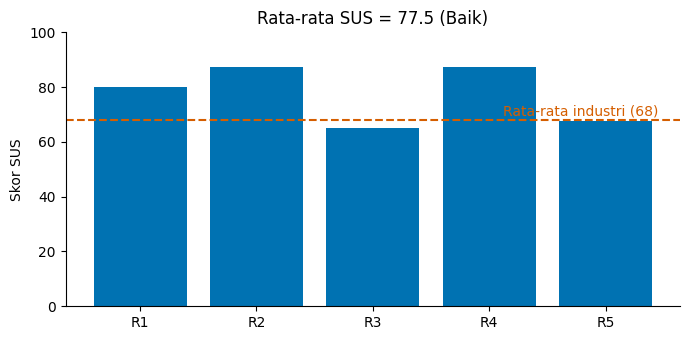

In [12]:
def skor_sus(jawaban):
    """Butir ganjil: (nilai-1). Butir genap: (5-nilai). Jumlah x 2.5 -> 0..100."""
    assert len(jawaban) == 10 and all(1 <= j <= 5 for j in jawaban), "Butuh 10 jawaban skala 1-5"
    total = sum((j-1) if i % 2 == 0 else (5-j) for i, j in enumerate(jawaban))
    return total * 2.5

responden = {
    "R1": [4, 2, 4, 1, 5, 2, 4, 2, 4, 2],
    "R2": [5, 1, 4, 2, 4, 1, 5, 1, 4, 2],
    "R3": [3, 2, 4, 2, 4, 3, 4, 2, 3, 3],
    "R4": [4, 1, 5, 1, 4, 2, 4, 2, 5, 1],
    "R5": [4, 2, 3, 2, 3, 2, 4, 3, 4, 2],
}
sus = pd.Series({k: skor_sus(v) for k, v in responden.items()}, name="Skor SUS")
rata = sus.mean()
kategori = "Sangat baik" if rata >= 80.3 else "Baik" if rata >= 68 else "Perlu perbaikan"

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(sus.index, sus.values, color="#0072B2")
ax.axhline(68, color="#D55E00", ls="--"); ax.text(4.45, 69.5, "Rata-rata industri (68)", ha="right", color="#D55E00")
ax.set_ylim(0, 100); ax.set_ylabel("Skor SUS"); ax.set_title(f"Rata-rata SUS = {rata:.1f} ({kategori})")
plt.tight_layout(); plt.savefig("grafik_sus.png", dpi=150, bbox_inches="tight"); plt.show()
sus.to_frame().to_csv("hasil_skor_sus.csv")

## 9. Ekspor Hasil untuk Repository
Menyimpan ringkasan CSV dan dashboard HTML interaktif (bisa dibuka langsung di browser tanpa Python).

In [13]:
import plotly.express as px

ringkasan = (df.groupby(["kota", "kategori"])
               .agg(total_penjualan=("penjualan", "sum"), jumlah_transaksi=("penjualan", "size"),
                    rata_rata=("penjualan", "mean"), total_iklan=("biaya_iklan", "sum"))
               .round(0).reset_index())
ringkasan.to_csv("hasil_ringkasan_kota.csv", index=False)

bulanan = df.groupby(["bulan", "kota"], as_index=False)["penjualan"].sum()
fig = px.line(bulanan, x="bulan", y="penjualan", color="kota", markers=True,
              color_discrete_sequence=["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9"],
              labels={"bulan": "Bulan", "penjualan": "Penjualan (Rp)", "kota": "Kota"},
              title="Dashboard Penjualan: klik legenda untuk menyaring kota, arahkan kursor untuk detail")
fig.update_layout(hovermode="x unified", template="simple_white")
fig.write_html("dashboard_penjualan.html", include_plotlyjs="cdn")
print("Tersimpan: hasil_ringkasan_kota.csv, dashboard_penjualan.html")
ringkasan.head()

Tersimpan: hasil_ringkasan_kota.csv, dashboard_penjualan.html


,kota,kategori,total_penjualan,jumlah_transaksi,rata_rata,total_iklan
0,Bandung,Elektronik,"1,696,251,000",225,"7,538,893","130,410,000"
1,Bandung,Fashion,"294,387,000",245,"1,201,580","22,039,000"
2,Bandung,Makanan,"66,125,000",186,"355,511","4,972,000"
3,Bandung,Rumah Tangga,"211,512,000",127,"1,665,449","16,234,000"
4,Jakarta,Elektronik,"3,227,656,000",427,"7,558,913","237,998,000"


## Kesimpulan
1. **Persona dan skenario** membuat desain berfokus pada kebutuhan Budi, bukan asumsi perancang.
2. **Non-functional requirement** (waktu muat, kontras) dapat diverifikasi dengan kode, bukan sekadar klaim.
3. **Pemilihan grafik** mengikuti tujuan analisis; **visualisasi jujur** menjaga etika (sumbu mulai dari 0).
4. **Warna, kontras, dan Gestalt** mengurangi beban kognitif (*extraneous load*) dan mendukung aksesibilitas.
5. Dashboard menerapkan pola **overview → zoom and filter → details on demand**.
6. **Heuristik Nielsen** dan **SUS** dipakai untuk mengevaluasi dan memperbaiki desain secara iteratif.

